LAB TASK 2 - GENERATE IMAGES FROM REAL CAPTIONS

[1] CHECKING GPU...
PyTorch Version: 2.11.0+cu128
CUDA Available: True
GPU: Tesla T4

[2] SEARCHING FOR FLICKR8K CAPTIONS FILE...
Caption file found:
/kaggle/input/datasets/abdullahmustafa1/image-generation/captions.txt

[3] LOADING CAPTIONS...
Total captions: 40455
Caption column: caption

First 5 captions:
                                             caption
0  A child in a pink dress is climbing up a set o...
1              A girl going into a wooden building .
2   A little girl climbing into a wooden playhouse .
3  A little girl climbing the stairs to her playh...
4  A little girl in a pink dress going into a woo...

[4] SELECTING THREE CAPTIONS...

Selected Captions:

Caption 1:
A large wild cat is pursuing a horse across a meadow .

Caption 2:
Two brown dogs fight on the leafy ground .

Caption 3:
A man in shorts is standing on a rock looking out at the view from the hilltop .

[5] LOADING SD-TURBO MODEL...
This may take a few minu

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  if local_dir_use_symlinks is not None:


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

...


Generating Image 2/3
Prompt: Two brown dogs fight on the leafy ground .


  0%|          | 0/2 [00:00<?, ?it/s]


Generating Image 3/3
Prompt: A man in shorts is standing on a rock looking out at the view from the hilltop .


  0%|          | 0/2 [00:00<?, ?it/s]


All 3 images generated successfully.

[7] DISPLAYING RESULTS...


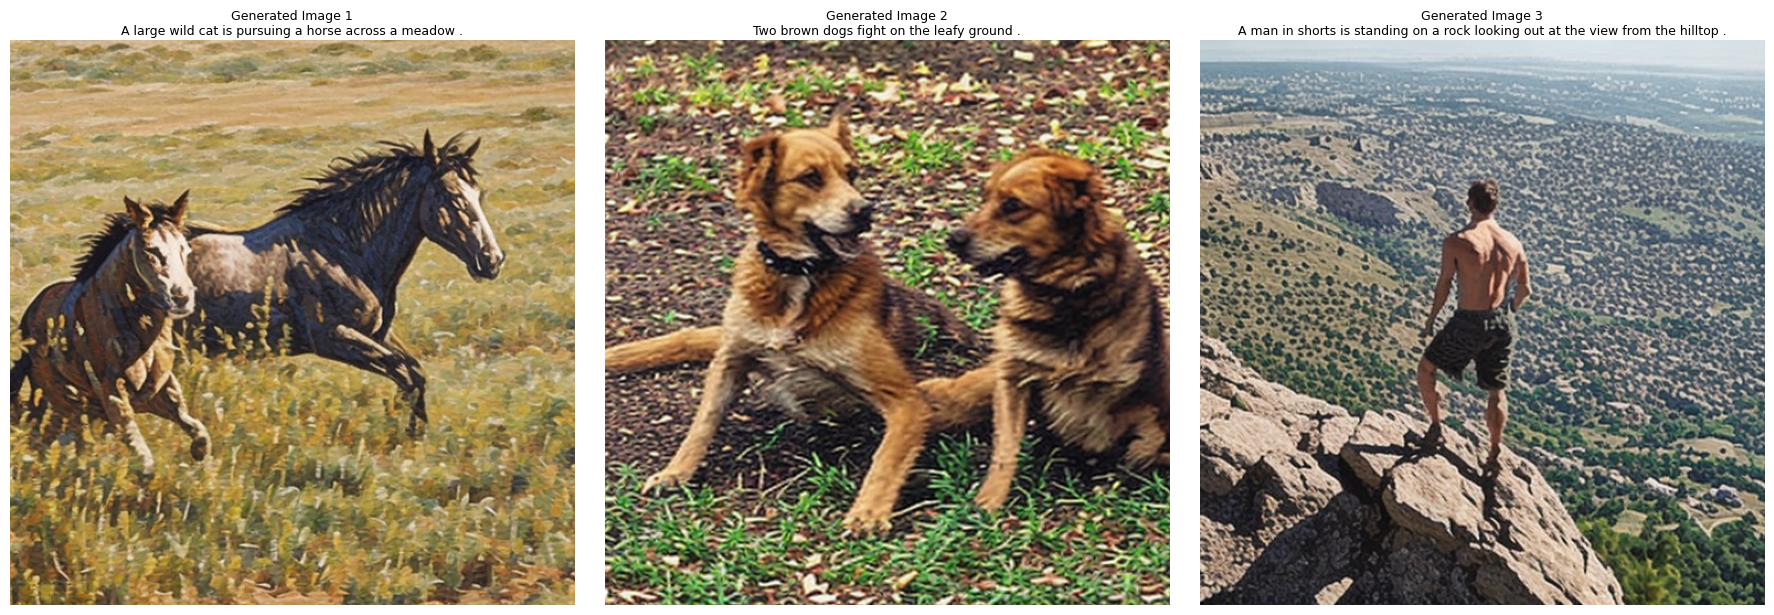


[8] SAVING IMAGES...
Saved: /kaggle/working/generated_images/generated_image_1.png
Saved: /kaggle/working/generated_images/generated_image_2.png
Saved: /kaggle/working/generated_images/generated_image_3.png

[9] INDIVIDUAL RESULTS

GENERATED IMAGE 1

Source Caption:
A large wild cat is pursuing a horse across a meadow .



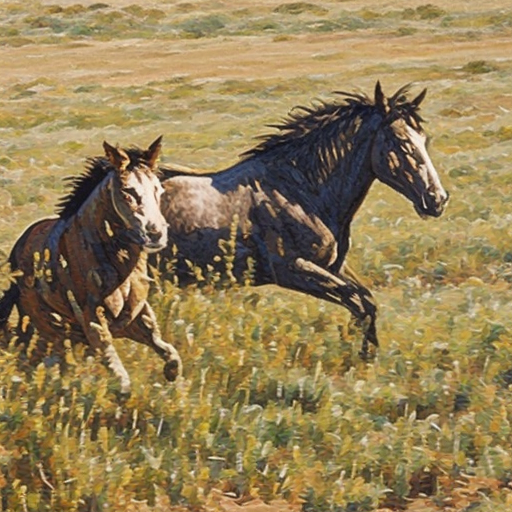


GENERATED IMAGE 2

Source Caption:
Two brown dogs fight on the leafy ground .



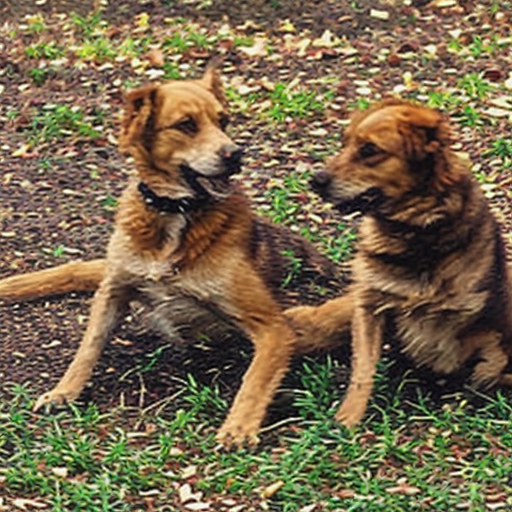


GENERATED IMAGE 3

Source Caption:
A man in shorts is standing on a rock looking out at the view from the hilltop .



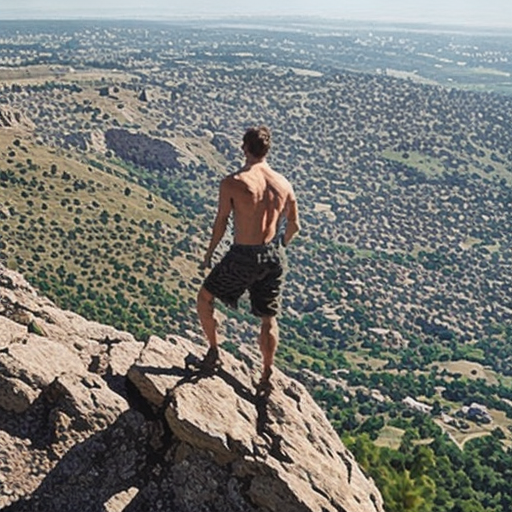


[10] EVALUATION TABLE


,Image,Source Caption,Caption Match,Visual Quality,Missing or Incorrect Details,Overall Evaluation
0,Generated Image 1,A large wild cat is pursuing a horse across a ...,Evaluate manually,Evaluate manually,Evaluate manually,Evaluate manually
1,Generated Image 2,Two brown dogs fight on the leafy ground .,Evaluate manually,Evaluate manually,Evaluate manually,Evaluate manually
2,Generated Image 3,A man in shorts is standing on a rock looking ...,Evaluate manually,Evaluate manually,Evaluate manually,Evaluate manually



Evaluation file saved:
/kaggle/working/evaluation_results.csv

TASK COMPLETED SUCCESSFULLY

Selected Captions:
1. A large wild cat is pursuing a horse across a meadow .
2. Two brown dogs fight on the leafy ground .
3. A man in shorts is standing on a rock looking out at the view from the hilltop .

Generated Images Folder:
/kaggle/working/generated_images

Evaluation CSV:
/kaggle/working/evaluation_results.csv


In [12]:
# ============================================================
# LAB TASK 2 - GENERATE IMAGES FROM REAL CAPTIONS
# Dataset: Flickr8k
# Model: SD-Turbo
# ============================================================

# -----------------------------
# 1. INSTALL REQUIRED LIBRARIES
# -----------------------------
!pip install -q diffusers transformers accelerate safetensors

# -----------------------------
# 2. IMPORT LIBRARIES
# -----------------------------
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt

from diffusers import AutoPipelineForText2Image
from PIL import Image

print("=" * 70)
print("LAB TASK 2 - GENERATE IMAGES FROM REAL CAPTIONS")
print("=" * 70)

# -----------------------------
# 3. CHECK GPU
# -----------------------------
print("\n[1] CHECKING GPU...")

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not enabled. Go to Kaggle Settings -> Accelerator -> GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))

# -----------------------------
# 4. FIND FLICKR8K CAPTION FILE
# -----------------------------
print("\n[2] SEARCHING FOR FLICKR8K CAPTIONS FILE...")

caption_file = None

possible_names = [
    "captions.txt",
    "flickr8k.token.txt",
    "flickr8k_token.txt"
]

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() in possible_names:
            caption_file = os.path.join(root, file)
            break

    if caption_file:
        break

if caption_file is None:
    print("\nFiles found inside /kaggle/input:\n")

    for root, dirs, files in os.walk("/kaggle/input"):
        for file in files[:10]:
            print(os.path.join(root, file))

    raise FileNotFoundError(
        "\nFlickr8k caption file not found. "
        "Please add the Flickr8k dataset using Kaggle Add Input."
    )

print("Caption file found:")
print(caption_file)

# -----------------------------
# 5. LOAD CAPTIONS
# -----------------------------
print("\n[3] LOADING CAPTIONS...")

try:
    captions_df = pd.read_csv(caption_file)

    # Detect caption column
    caption_column = None

    for col in captions_df.columns:
        if "caption" in col.lower():
            caption_column = col
            break

    if caption_column is None:
        raise ValueError("Caption column not detected.")

except:
    print("Standard CSV format not detected.")
    print("Trying Flickr8k token format...")

    rows = []

    with open(caption_file, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            parts = line.split("\t")

            if len(parts) >= 2:
                image_name = parts[0].split("#")[0]
                caption = parts[1]

                rows.append({
                    "image": image_name,
                    "caption": caption
                })

    captions_df = pd.DataFrame(rows)
    caption_column = "caption"

if len(captions_df) < 3:
    raise ValueError("Not enough captions found in dataset.")

print("Total captions:", len(captions_df))
print("Caption column:", caption_column)

print("\nFirst 5 captions:")
print(captions_df[[caption_column]].head())

# -----------------------------
# 6. SELECT 3 REAL CAPTIONS
# -----------------------------
print("\n[4] SELECTING THREE CAPTIONS...")

sampled = captions_df.sample(
    n=3,
    random_state=42
)

captions = sampled[caption_column].astype(str).tolist()

print("\nSelected Captions:")

for i, caption in enumerate(captions, start=1):
    print(f"\nCaption {i}:")
    print(caption)

# -----------------------------
# 7. LOAD SD-TURBO
# -----------------------------
print("\n[5] LOADING SD-TURBO MODEL...")
print("This may take a few minutes the first time.")

model_id = "stabilityai/sd-turbo"

pipe = AutoPipelineForText2Image.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    variant="fp16"
)

pipe = pipe.to("cuda")

# Memory optimization
pipe.enable_attention_slicing()

print("SD-Turbo loaded successfully.")

# -----------------------------
# 8. GENERATE 3 IMAGES
# -----------------------------
print("\n[6] GENERATING IMAGES...")

generated_images = []

for i, caption in enumerate(captions, start=1):

    print(f"\nGenerating Image {i}/3")
    print("Prompt:", caption)

    image = pipe(
        prompt=caption,
        num_inference_steps=2,
        guidance_scale=0.0,
        height=512,
        width=512
    ).images[0]

    generated_images.append(image)

print("\nAll 3 images generated successfully.")

# -----------------------------
# 9. DISPLAY GENERATED IMAGES
# -----------------------------
print("\n[7] DISPLAYING RESULTS...")

plt.figure(figsize=(18, 6))

for i, image in enumerate(generated_images):

    plt.subplot(1, 3, i + 1)

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"Generated Image {i+1}\n{captions[i]}",
        fontsize=9,
        wrap=True
    )

plt.tight_layout()
plt.show()

# -----------------------------
# 10. SAVE IMAGES
# -----------------------------
print("\n[8] SAVING IMAGES...")

output_dir = "/kaggle/working/generated_images"

os.makedirs(
    output_dir,
    exist_ok=True
)

for i, image in enumerate(generated_images, start=1):

    path = f"{output_dir}/generated_image_{i}.png"

    image.save(path)

    print("Saved:", path)

# -----------------------------
# 11. DISPLAY EACH IMAGE SEPARATELY
# -----------------------------
print("\n[9] INDIVIDUAL RESULTS")

for i in range(3):

    print("\n" + "=" * 70)
    print(f"GENERATED IMAGE {i+1}")
    print("=" * 70)

    print("\nSource Caption:")
    print(captions[i])

    print()

    display(generated_images[i])

# -----------------------------
# 12. CREATE EVALUATION TABLE
# -----------------------------
print("\n[10] EVALUATION TABLE")

evaluation_df = pd.DataFrame({

    "Image": [
        "Generated Image 1",
        "Generated Image 2",
        "Generated Image 3"
    ],

    "Source Caption": captions,

    "Caption Match": [
        "Evaluate manually",
        "Evaluate manually",
        "Evaluate manually"
    ],

    "Visual Quality": [
        "Evaluate manually",
        "Evaluate manually",
        "Evaluate manually"
    ],

    "Missing or Incorrect Details": [
        "Evaluate manually",
        "Evaluate manually",
        "Evaluate manually"
    ],

    "Overall Evaluation": [
        "Evaluate manually",
        "Evaluate manually",
        "Evaluate manually"
    ]

})

display(evaluation_df)

# -----------------------------
# 13. SAVE EVALUATION TABLE
# -----------------------------
evaluation_path = "/kaggle/working/evaluation_results.csv"

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

print("\nEvaluation file saved:")
print(evaluation_path)

# -----------------------------
# 14. FINAL SUMMARY
# -----------------------------
print("\n" + "=" * 70)
print("TASK COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nSelected Captions:")

for i, caption in enumerate(captions, start=1):
    print(f"{i}. {caption}")

print("\nGenerated Images Folder:")
print(output_dir)

print("\nEvaluation CSV:")
print(evaluation_path)

LAB TASK 2 - GENERATE IMAGES FROM CUSTOM PROMPTS

[1] CHECKING GPU...
PyTorch Version: 2.11.0+cu128
CUDA Available: True
GPU: Tesla T4

[2] CUSTOM PROMPTS

Prompt 1:
A futuristic neon city at night with flying cars, cinematic lighting, highly detailed

Prompt 2:
A soldier standing inside a futuristic sci-fi military base, realistic, dramatic lighting, detailed environment

Prompt 3:
A small robot walking through an abandoned laboratory, cinematic atmosphere, volumetric lighting, highly detailed

[3] LOADING SD-TURBO MODEL...
First run may take a few minutes.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


...

Image 1 generated successfully!

------------------------------------------------------------
Generating Image 2/3
Prompt:
A soldier standing inside a futuristic sci-fi military base, realistic, dramatic lighting, detailed environment


  0%|          | 0/2 [00:00<?, ?it/s]

Image 2 generated successfully!

------------------------------------------------------------
Generating Image 3/3
Prompt:
A small robot walking through an abandoned laboratory, cinematic atmosphere, volumetric lighting, highly detailed


  0%|          | 0/2 [00:00<?, ?it/s]

Image 3 generated successfully!

All images generated successfully!

[5] DISPLAYING ALL RESULTS...


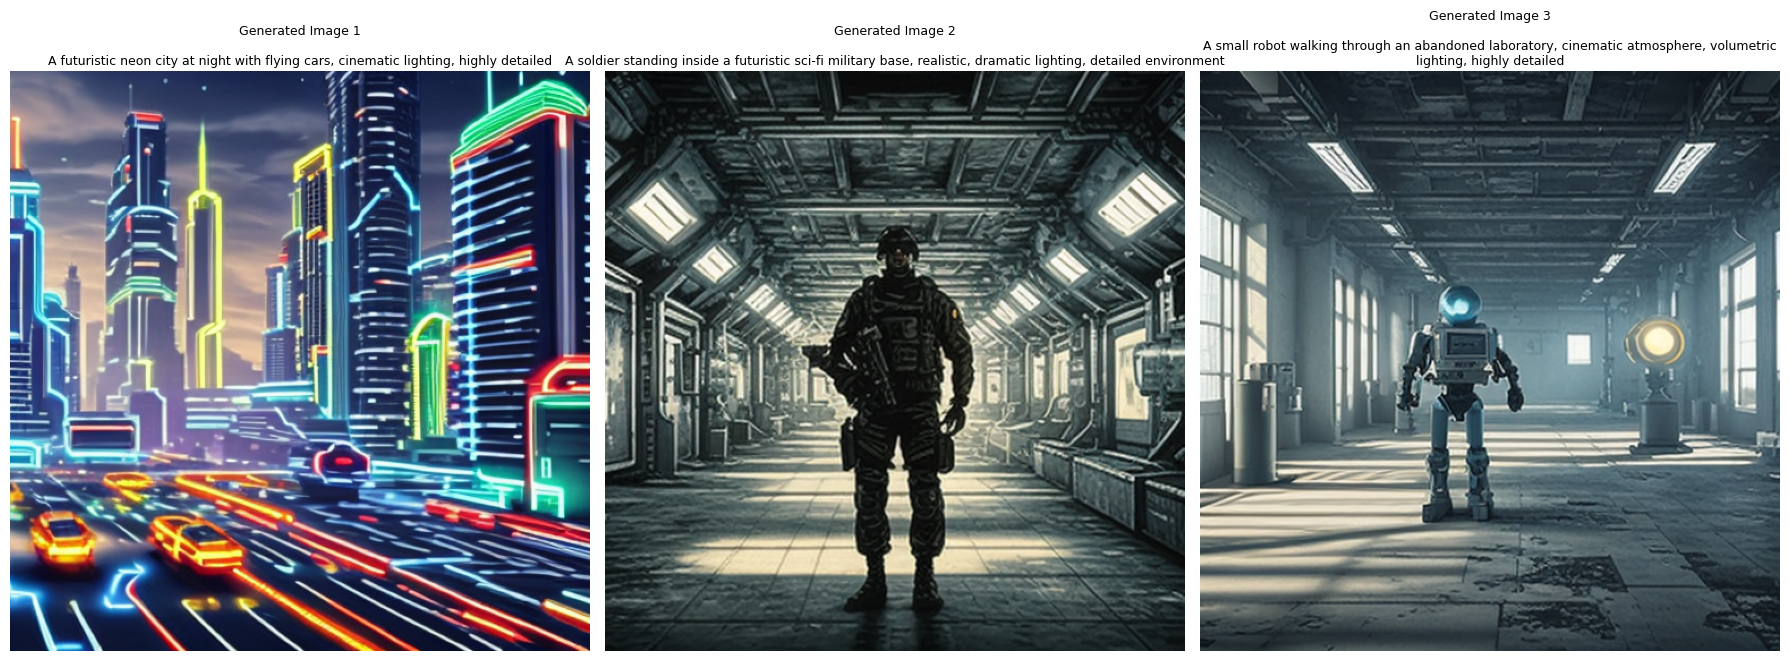


[6] CREATING OUTPUT FOLDER...
Output folder:
/kaggle/working/generated_images

[7] SAVING GENERATED IMAGES...
Image 1 saved:
/kaggle/working/generated_images/generated_image_1.png
Image 2 saved:
/kaggle/working/generated_images/generated_image_2.png
Image 3 saved:
/kaggle/working/generated_images/generated_image_3.png

[8] INDIVIDUAL RESULTS

GENERATED IMAGE 1

Prompt:
A futuristic neon city at night with flying cars, cinematic lighting, highly detailed

Generated Result:


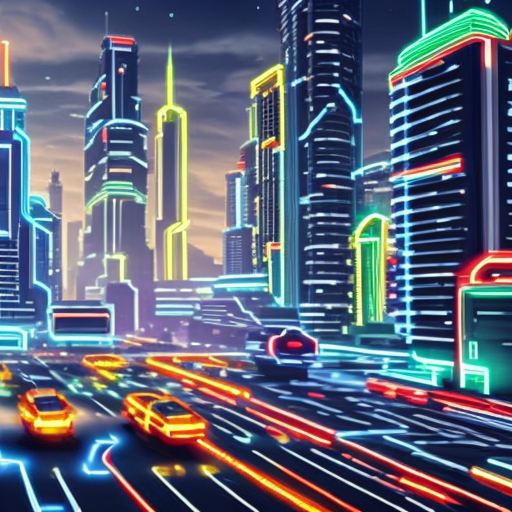


GENERATED IMAGE 2

Prompt:
A soldier standing inside a futuristic sci-fi military base, realistic, dramatic lighting, detailed environment

Generated Result:


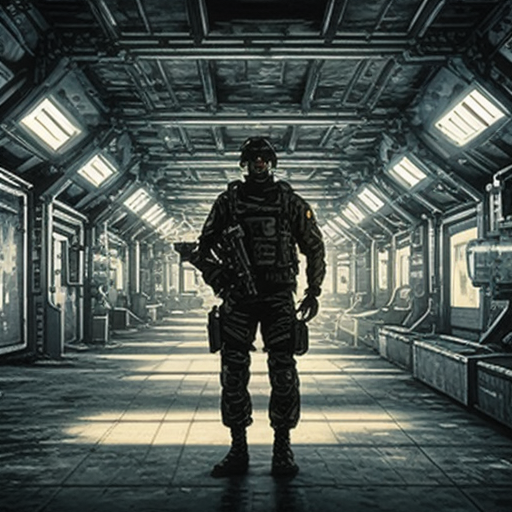


GENERATED IMAGE 3

Prompt:
A small robot walking through an abandoned laboratory, cinematic atmosphere, volumetric lighting, highly detailed

Generated Result:


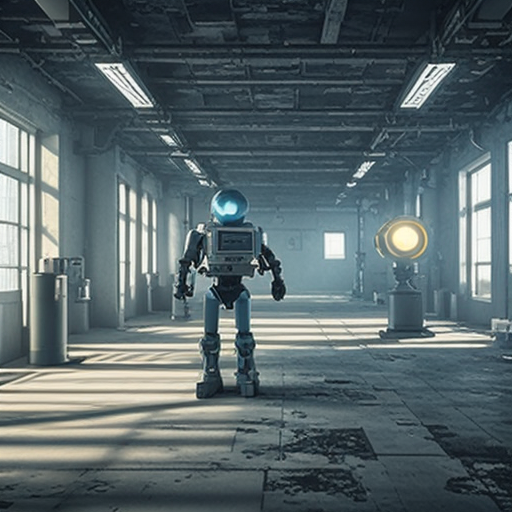


[9] CREATING EVALUATION TABLE...


,Image,Prompt,Prompt Match,Visual Quality,Missing or Incorrect Details,Overall Evaluation
0,Generated Image 1,A futuristic neon city at night with flying ca...,Evaluate manually,Evaluate manually,Evaluate manually,Evaluate manually
1,Generated Image 2,A soldier standing inside a futuristic sci-fi ...,Evaluate manually,Evaluate manually,Evaluate manually,Evaluate manually
2,Generated Image 3,A small robot walking through an abandoned lab...,Evaluate manually,Evaluate manually,Evaluate manually,Evaluate manually



Evaluation CSV saved:
/kaggle/working/evaluation_results.csv

TASK COMPLETED SUCCESSFULLY

Prompts Used:

1. A futuristic neon city at night with flying cars, cinematic lighting, highly detailed

2. A soldier standing inside a futuristic sci-fi military base, realistic, dramatic lighting, detailed environment

3. A small robot walking through an abandoned laboratory, cinematic atmosphere, volumetric lighting, highly detailed

Generated Images:
/kaggle/working/generated_images/generated_image_1.png
/kaggle/working/generated_images/generated_image_2.png
/kaggle/working/generated_images/generated_image_3.png

Evaluation CSV:
/kaggle/working/evaluation_results.csv

END OF LAB TASK 2


In [2]:
# ============================================================
# LAB TASK 2 - GENERATE IMAGES FROM CUSTOM PROMPTS
# Model: SD-Turbo
# ============================================================

# ------------------------------------------------------------
# 1. INSTALL REQUIRED LIBRARIES
# ------------------------------------------------------------
!pip install -q diffusers transformers accelerate safetensors


# ------------------------------------------------------------
# 2. IMPORT LIBRARIES
# ------------------------------------------------------------
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt

from diffusers import AutoPipelineForText2Image
from IPython.display import display


print("=" * 70)
print("LAB TASK 2 - GENERATE IMAGES FROM CUSTOM PROMPTS")
print("=" * 70)


# ------------------------------------------------------------
# 3. CHECK GPU
# ------------------------------------------------------------
print("\n[1] CHECKING GPU...")

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not enabled. "
        "Go to Kaggle Settings -> Accelerator -> GPU."
    )

print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 4. MY PROMPTS
# ============================================================
# ONLY CHANGE THESE PROMPTS
# Write whatever images you want to generate.

prompts = [

    "islamabad at night with flying cars, cinematic lighting, highly detailed",

    "A batman standing inside a futuristic sci-fi military base, realistic, dramatic lighting, detailed environment",

    "A small robot walking through library, cinematic atmosphere, volumetric lighting, highly detailed"
    

]


print("\n[2] CUSTOM PROMPTS")

for i, prompt in enumerate(prompts, start=1):
    print(f"\nPrompt {i}:")
    print(prompt)


# ------------------------------------------------------------
# 5. LOAD SD-TURBO MODEL
# ------------------------------------------------------------
print("\n[3] LOADING SD-TURBO MODEL...")
print("First run may take a few minutes.")

model_id = "stabilityai/sd-turbo"

pipe = AutoPipelineForText2Image.from_pretrained(
    model_id,
    torch_dtype=torch.float16,
    variant="fp16"
)

pipe = pipe.to("cuda")

# Helps reduce GPU memory usage
pipe.enable_attention_slicing()

print("\nSD-Turbo loaded successfully!")


# ------------------------------------------------------------
# 6. GENERATE IMAGES
# ------------------------------------------------------------
print("\n[4] GENERATING IMAGES...")

generated_images = []

for i, prompt in enumerate(prompts, start=1):

    print("\n" + "-" * 60)
    print(f"Generating Image {i}/{len(prompts)}")
    print("Prompt:")
    print(prompt)

    image = pipe(
        prompt=prompt,
        num_inference_steps=2,
        guidance_scale=0.0,
        height=512,
        width=512
    ).images[0]

    generated_images.append(image)

    print(f"Image {i} generated successfully!")


print("\nAll images generated successfully!")


# ------------------------------------------------------------
# 7. DISPLAY ALL IMAGES TOGETHER
# ------------------------------------------------------------
print("\n[5] DISPLAYING ALL RESULTS...")

plt.figure(figsize=(18, 7))

for i, image in enumerate(generated_images):

    plt.subplot(1, len(generated_images), i + 1)

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"Generated Image {i + 1}\n\n{prompts[i]}",
        fontsize=9,
        wrap=True
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. CREATE OUTPUT FOLDER
# ------------------------------------------------------------
print("\n[6] CREATING OUTPUT FOLDER...")

output_dir = "/kaggle/working/generated_images"

os.makedirs(
    output_dir,
    exist_ok=True
)

print("Output folder:")
print(output_dir)


# ------------------------------------------------------------
# 9. SAVE GENERATED IMAGES
# ------------------------------------------------------------
print("\n[7] SAVING GENERATED IMAGES...")

saved_paths = []

for i, image in enumerate(generated_images, start=1):

    image_path = os.path.join(
        output_dir,
        f"generated_image_{i}.png"
    )

    image.save(image_path)

    saved_paths.append(image_path)

    print(f"Image {i} saved:")
    print(image_path)


# ------------------------------------------------------------
# 10. DISPLAY EACH IMAGE SEPARATELY
# ------------------------------------------------------------
print("\n[8] INDIVIDUAL RESULTS")

for i, image in enumerate(generated_images):

    print("\n" + "=" * 70)
    print(f"GENERATED IMAGE {i + 1}")
    print("=" * 70)

    print("\nPrompt:")
    print(prompts[i])

    print("\nGenerated Result:")

    display(image)


# ------------------------------------------------------------
# 11. CREATE EVALUATION TABLE
# ------------------------------------------------------------
print("\n[9] CREATING EVALUATION TABLE...")

evaluation_df = pd.DataFrame({

    "Image": [
        f"Generated Image {i + 1}"
        for i in range(len(prompts))
    ],

    "Prompt": prompts,

    "Prompt Match": [
        "Evaluate manually"
        for _ in prompts
    ],

    "Visual Quality": [
        "Evaluate manually"
        for _ in prompts
    ],

    "Missing or Incorrect Details": [
        "Evaluate manually"
        for _ in prompts
    ],

    "Overall Evaluation": [
        "Evaluate manually"
        for _ in prompts
    ]

})


display(evaluation_df)


# ------------------------------------------------------------
# 12. SAVE EVALUATION TABLE
# ------------------------------------------------------------
evaluation_path = (
    "/kaggle/working/evaluation_results.csv"
)

evaluation_df.to_csv(
    evaluation_path,
    index=False
)

print("\nEvaluation CSV saved:")
print(evaluation_path)


# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("TASK COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nPrompts Used:")

for i, prompt in enumerate(prompts, start=1):
    print(f"\n{i}. {prompt}")


print("\nGenerated Images:")

for path in saved_paths:
    print(path)


print("\nEvaluation CSV:")
print(evaluation_path)

print("\n" + "=" * 70)
print("END OF LAB TASK 2")
print("=" * 70)

In [1]:
# ============================================================
# LAB TASK 1: GENERATE AND EVALUATE STORY COMPLETIONS
# Single Kaggle Cell
# ============================================================

%pip install -q "transformers>=4.40,<5"

import re
from pathlib import Path

import torch
import pandas as pd
from IPython.display import display
from transformers import pipeline, set_seed

# 1. FIND DATASET
source_files = sorted(Path("/kaggle/input").rglob("*.wp_source"))

if not source_files:
    raise FileNotFoundError(
        "Add Input se ratthachat/writing-prompts dataset add karo, "
        "phir cell dobara run karo."
    )

source_file = next(
    (p for p in source_files if p.name == "test.wp_source"),
    source_files[0]
)

# 2. LOAD FIVE REAL PROMPTS
prompts = []

with open(source_file, "r", encoding="utf-8") as file:
    for line in file:
        prompt = line.strip()
        prompt = re.sub(r"^\s*\[\s*\w+\s*\]\s*", "", prompt)
        prompt = prompt.replace("<newline>", " ").strip()

        if prompt and prompt not in prompts:
            prompts.append(prompt)

        if len(prompts) == 5:
            break

if len(prompts) != 5:
    raise ValueError("Dataset mein 5 unique prompts nahi mile.")

print("\nFIVE DATASET PROMPTS\n")

for number, prompt in enumerate(prompts, 1):
    print(f"{number}. {prompt}\n")

confirmation = input("Prompts parh liye? Generation ke liye yes likho: ")

if confirmation.strip().lower() != "yes":
    raise SystemExit("Generation stopped. Prompts parh kar cell dobara run karo.")

# 3. LOAD GPT-2
set_seed(42)

generator = pipeline(
    "text-generation",
    model="openai-community/gpt2",
    device=0 if torch.cuda.is_available() else -1
)

generator.tokenizer.pad_token = generator.tokenizer.eos_token

print("\nModel loaded!")
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

# 4. GENERATE ONE COMPLETION PER PROMPT
results = []

for number, prompt in enumerate(prompts, 1):
    input_text = prompt + "\n\n"
    input_length = len(generator.tokenizer.encode(input_text))
    token_budget = generator.model.config.n_positions - input_length

    if token_budget < 1:
        raise ValueError(f"Prompt {number} GPT-2 context limit se lamba hai.")

    output = generator(
        input_text,
        max_new_tokens=min(180, token_budget),
        do_sample=True,
        temperature=0.8,
        top_p=0.95,
        top_k=50,
        repetition_penalty=1.1,
        num_return_sequences=1,
        return_full_text=False,
        pad_token_id=generator.tokenizer.eos_token_id
    )

    completion = output[0]["generated_text"].strip()

    results.append({
        "No": number,
        "Prompt": prompt,
        "Completion": completion
    })

    print("\n" + "=" * 80)
    print(f"STORY {number}")
    print("=" * 80)
    print("\nPROMPT:\n" + prompt)
    print("\nCOMPLETION:\n" + completion)

# 5. SAVE STORIES
output_folder = Path("/kaggle/working")
output_folder.mkdir(parents=True, exist_ok=True)

pd.DataFrame(results).to_csv(
    output_folder / "story_completions.csv",
    index=False
)

# 6. MANUAL EVALUATION
print("\nHar story parh kar 1–5 marks do.")
print("Coherence: Story ka flow aur logical connection.")
print("Relevance: Story prompt ko kitna follow karti hai.")
print("Factual Plausibility: Details story ke context mein kitni believable hain.")

def get_score(label):
    while True:
        try:
            score = int(input(label))
            if 1 <= score <= 5:
                return score
        except ValueError:
            pass
        print("Sirf 1 se 5 tak whole number likho.")

evaluations = []

for result in results:
    print("\n" + "-" * 80)
    print(f"STORY {result['No']}")
    print("\nPrompt:", result["Prompt"])
    print("\nCompletion:", result["Completion"], "\n")

    evaluations.append({
        "No": result["No"],
        "Coherence (1–5)": get_score("Coherence (1–5): "),
        "Relevance (1–5)": get_score("Relevance (1–5): "),
        "Factual Plausibility (1–5)": get_score(
            "Factual Plausibility (1–5): "
        ),
        "Notes": input("Short observation / notes: ")
    })

evaluation_df = pd.DataFrame(evaluations)

print("\nFINAL EVALUATION TABLE")
display(evaluation_df)

evaluation_df.to_csv(
    output_folder / "story_evaluation.csv",
    index=False
)

print("\nTask complete! Files saved:")
print("/kaggle/working/story_completions.csv")
print("/kaggle/working/story_evaluation.csv")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 92.7 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 64.8 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


FileNotFoundError: Add Input se ratthachat/writing-prompts dataset add karo, phir cell dobara run karo.